# EDA датасета METABRIC

Датасет содержит клинические и генетические признаки пациентов с раком молочной железы. Цель анализа — оценить структуру и качество данных, найти пропуски, дубликаты, аномалии и выбросы, а также посмотреть основные распределения и связи между признаками.

В анализе используются обработанные данные из `data/METABRIC_RNA_Mutation.parquet`. Файл данных не хранится в GitHub и создаётся скриптом `data_loader.py`.

## 1. Загрузка данных

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda value: f"{value:.2f}")

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
os.chdir(project_root)

data_path = Path("data/METABRIC_RNA_Mutation.parquet")
if not data_path.exists():
    from data_loader import load_data
    load_data()

df = pd.read_parquet(data_path)
print(f"Размер датасета: {df.shape[0]} строк и {df.shape[1]} столбцов")

Размер датасета: 1904 строк и 693 столбцов


In [2]:
preview_columns = [
    "patient_id",
    "age_at_diagnosis",
    "cancer_type",
    "cellularity",
    "chemotherapy",
    "er_status",
    "her2_status",
    "tumor_size",
]
df[preview_columns].head()

,patient_id,age_at_diagnosis,cancer_type,cellularity,chemotherapy,er_status,her2_status,tumor_size
0,0,75.65,Breast Cancer,NaN,False,Positive,Negative,22.00
1,2,43.19,Breast Cancer,High,False,Positive,Negative,10.00
2,5,48.87,Breast Cancer,High,True,Positive,Negative,15.00
3,6,47.68,Breast Cancer,Moderate,True,Positive,Negative,25.00
4,8,76.97,Breast Cancer,High,True,Positive,Negative,40.00


Первые строки показывают, что одна строка соответствует одному пациенту. Для компактности выведены только восемь клинических столбцов из 693.

## 2. Структура данных

In [3]:
clinical_columns = list(df.columns[:31])
mutation_columns = [column for column in df.columns if column.endswith("_mut")]
expression_columns = [
    column
    for column in df.columns
    if column not in clinical_columns and column not in mutation_columns
]

structure = pd.DataFrame(
    {
        "Группа признаков": ["Клинические", "Экспрессия генов", "Мутации"],
        "Количество столбцов": [
            len(clinical_columns),
            len(expression_columns),
            len(mutation_columns),
        ],
    }
)
structure

,Группа признаков,Количество столбцов
0,Клинические,31
1,Экспрессия генов,489
2,Мутации,173


In [4]:
def dtype_name(dtype):
    if isinstance(dtype, pd.CategoricalDtype):
        return "category"
    if pd.api.types.is_bool_dtype(dtype):
        return "boolean"
    if pd.api.types.is_integer_dtype(dtype):
        return "integer"
    if pd.api.types.is_float_dtype(dtype):
        return "float"
    return "string"

dtype_summary = (
    pd.Series([dtype_name(dtype) for dtype in df.dtypes])
    .value_counts()
    .rename_axis("Тип")
    .reset_index(name="Количество столбцов")
)
dtype_summary

,Тип,Количество столбцов
0,float,493
1,boolean,177
2,category,17
3,integer,5
4,string,1


Данные состоят из 31 клинического признака, 489 показателей экспрессии и 173 признаков мутаций. Генетические значения в основном числовые, мутации хранятся как логические признаки, а клинические категории имеют тип `category`.

## 3. Метрики качества данных

In [5]:
quality_metrics = pd.DataFrame(
    {
        "Метрика": [
            "Количество строк",
            "Количество столбцов",
            "Полнота всех ячеек, %",
            "Строки хотя бы с одним пропуском, %",
            "Полные дубликаты",
            "Дубликаты patient_id",
            "Размер в памяти, МБ",
        ],
        "Значение": [
            len(df),
            df.shape[1],
            (1 - df.isna().mean().mean()) * 100,
            df.isna().any(axis=1).mean() * 100,
            df.duplicated().sum(),
            df["patient_id"].duplicated().sum(),
            df.memory_usage(deep=True).sum() / 1024**2,
        ],
    }
)
quality_metrics

,Метрика,Значение
0,Количество строк,1904.00
1,Количество столбцов,693.00
2,"Полнота всех ячеек, %",99.92
3,"Строки хотя бы с одним пропуском, %",42.65
4,Полные дубликаты,0.00
5,Дубликаты patient_id,0.00
6,"Размер в памяти, МБ",7.94


In [6]:
missing_by_group = pd.DataFrame(
    {
        "Группа": ["Клинические", "Экспрессия генов", "Мутации"],
        "Средняя доля пропусков, %": [
            df[clinical_columns].isna().mean().mean() * 100,
            df[expression_columns].isna().mean().mean() * 100,
            df[mutation_columns].isna().mean().mean() * 100,
        ],
    }
)
missing_by_group

,Группа,"Средняя доля пропусков, %"
0,Клинические,1.86
1,Экспрессия генов,0.00
2,Мутации,0.00


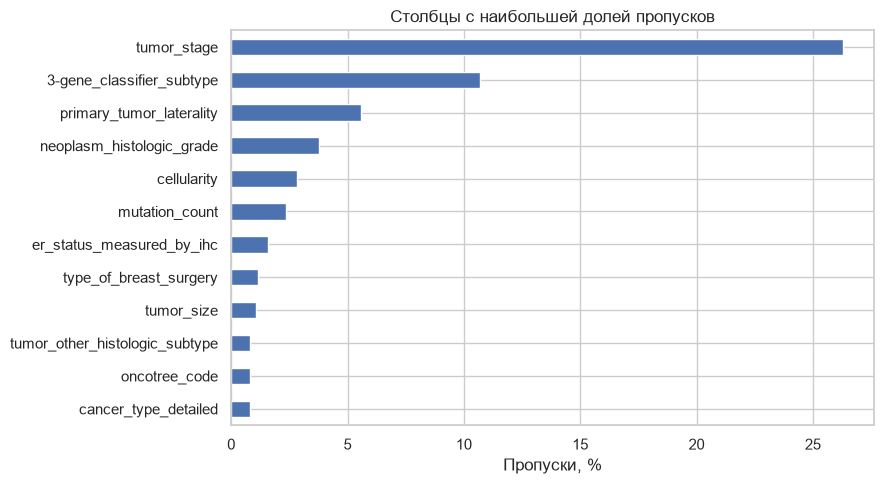

In [7]:
missing_rate = df.isna().mean().mul(100).sort_values(ascending=False)
missing_rate = missing_rate[missing_rate > 0].head(12).sort_values()

plt.figure(figsize=(9, 5))
missing_rate.plot(kind="barh")
plt.title("Столбцы с наибольшей долей пропусков")
plt.xlabel("Пропуски, %")
plt.ylabel("")
plt.tight_layout()
plt.show()

Общая полнота высокая — около **99,92%**, дубликатов строк и идентификаторов нет. При этом **42,65% строк** содержат хотя бы один пропуск. Причина — несколько клинических полей: у `tumor_stage` отсутствует 26,31% значений, у `3-gene_classifier_subtype` — 10,71%. В показателях экспрессии и мутаций пропусков нет.

## 4. Распределения клинических признаков

In [8]:
numeric_columns = [
    "age_at_diagnosis",
    "tumor_size",
    "tumor_stage",
    "lymph_nodes_examined_positive",
    "mutation_count",
    "nottingham_prognostic_index",
    "overall_survival_months",
]

df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
age_at_diagnosis,1904.00,61.09,12.98,21.93,51.38,61.77,70.59,96.29
tumor_size,1884.00,26.24,15.16,1.00,17.00,23.00,30.00,182.00
tumor_stage,1403.00,1.75,0.63,0.00,1.00,2.00,2.00,4.00
lymph_nodes_examined_positive,1904.00,2.00,4.08,0.00,0.00,0.00,2.00,45.00
mutation_count,1859.00,5.70,4.06,1.00,3.00,5.00,7.00,80.00
nottingham_prognostic_index,1904.00,4.03,1.14,1.00,3.05,4.04,5.04,6.36
overall_survival_months,1904.00,125.12,76.33,0.00,60.83,115.62,184.72,355.20


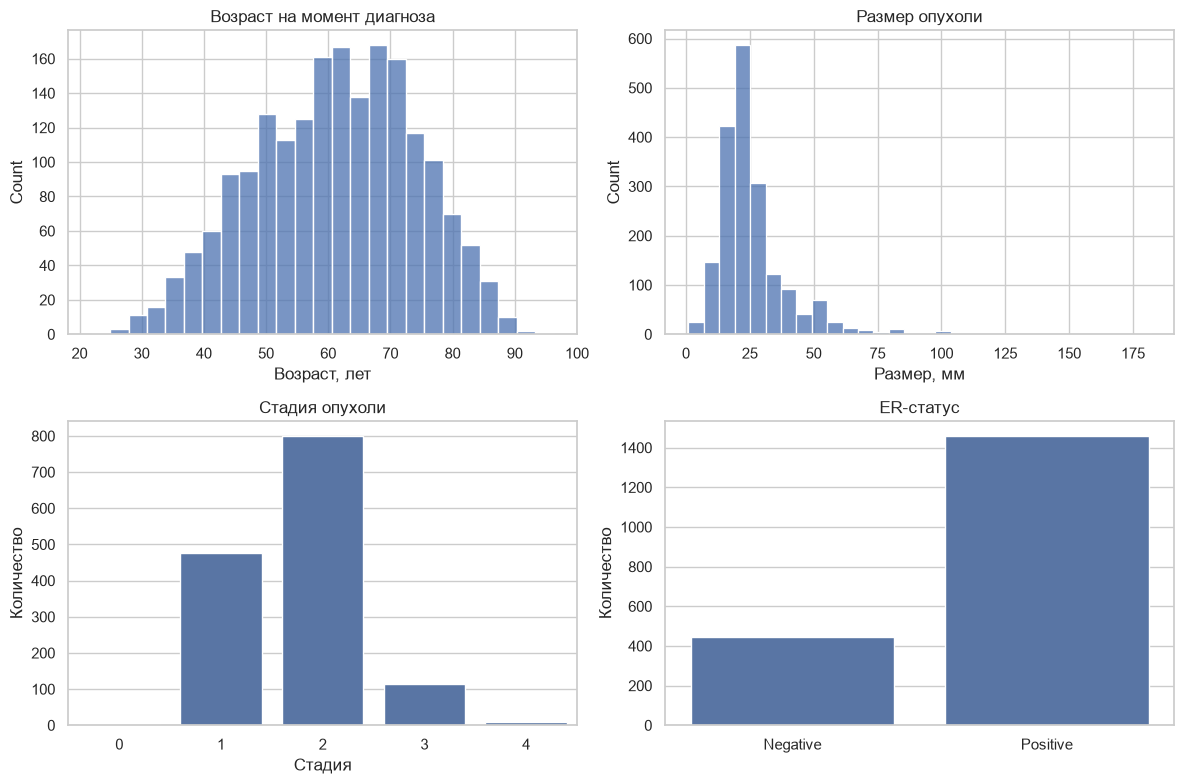

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df["age_at_diagnosis"], bins=25, ax=axes[0, 0])
axes[0, 0].set_title("Возраст на момент диагноза")
axes[0, 0].set_xlabel("Возраст, лет")

sns.histplot(df["tumor_size"], bins=30, ax=axes[0, 1])
axes[0, 1].set_title("Размер опухоли")
axes[0, 1].set_xlabel("Размер, мм")

sns.countplot(data=df, x="tumor_stage", ax=axes[1, 0])
axes[1, 0].set_title("Стадия опухоли")
axes[1, 0].set_xlabel("Стадия")
axes[1, 0].set_ylabel("Количество")

sns.countplot(data=df, x="er_status", ax=axes[1, 1])
axes[1, 1].set_title("ER-статус")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("Количество")

plt.tight_layout()
plt.show()

In [10]:
category_summary = pd.DataFrame(
    {
        "Признак": ["ER positive", "HER2 positive", "PR positive", "Overall survival"],
        "Количество": [
            (df["er_status"] == "Positive").sum(),
            (df["her2_status"] == "Positive").sum(),
            (df["pr_status"] == "Positive").sum(),
            df["overall_survival"].sum(),
        ],
        "Доля, %": [
            (df["er_status"] == "Positive").mean() * 100,
            (df["her2_status"] == "Positive").mean() * 100,
            (df["pr_status"] == "Positive").mean() * 100,
            df["overall_survival"].mean() * 100,
        ],
    }
)
category_summary

,Признак,Количество,"Доля, %"
0,ER positive,1459,76.63
1,HER2 positive,236,12.39
2,PR positive,1009,52.99
3,Overall survival,801,42.07


Возраст находится в диапазоне от 21,93 до 96,29 года, медиана — 61,77 года. Большинство опухолей относятся ко второй стадии, но для 501 пациента стадия не указана. ER-положительных наблюдений заметно больше, чем ER-отрицательных, а HER2-положительных — меньшинство. Это важно учитывать при будущем разбиении данных и моделировании.

## 5. Выбросы и аномалии

In [11]:
anomaly_checks = pd.DataFrame(
    {
        "Проверка": [
            "Возраст меньше 18 лет",
            "Возраст больше 100 лет",
            "Размер опухоли не больше 0",
            "Размер опухоли больше 200 мм",
            "Отрицательная длительность наблюдения",
            "Отрицательное число положительных лимфоузлов",
            "Стадия вне диапазона 0–4",
        ],
        "Количество": [
            (df["age_at_diagnosis"] < 18).sum(),
            (df["age_at_diagnosis"] > 100).sum(),
            (df["tumor_size"] <= 0).sum(),
            (df["tumor_size"] > 200).sum(),
            (df["overall_survival_months"] < 0).sum(),
            (df["lymph_nodes_examined_positive"] < 0).sum(),
            ((df["tumor_stage"] < 0) | (df["tumor_stage"] > 4)).sum(),
        ],
    }
)
anomaly_checks

,Проверка,Количество
0,Возраст меньше 18 лет,0
1,Возраст больше 100 лет,0
2,Размер опухоли не больше 0,0
3,Размер опухоли больше 200 мм,0
4,Отрицательная длительность наблюдения,0
5,Отрицательное число положительных лимфоузлов,0
6,Стадия вне диапазона 0–4,0


In [12]:
def iqr_outliers(series):
    series = series.dropna().astype(float)
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    mask = (series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)
    return mask.sum(), mask.mean() * 100


outlier_columns = [
    "age_at_diagnosis",
    "tumor_size",
    "lymph_nodes_examined_positive",
    "mutation_count",
    "nottingham_prognostic_index",
    "overall_survival_months",
]

outlier_rows = []
for column in outlier_columns:
    count, share = iqr_outliers(df[column])
    outlier_rows.append(
        {"Признак": column, "Количество выбросов": count, "Доля, %": share}
    )

outlier_summary = pd.DataFrame(outlier_rows).sort_values(
    "Количество выбросов", ascending=False
)
outlier_summary

,Признак,Количество выбросов,"Доля, %"
2,lymph_nodes_examined_positive,210,11.03
1,tumor_size,142,7.54
3,mutation_count,62,3.34
0,age_at_diagnosis,1,0.05
4,nottingham_prognostic_index,0,0.00
5,overall_survival_months,0,0.00


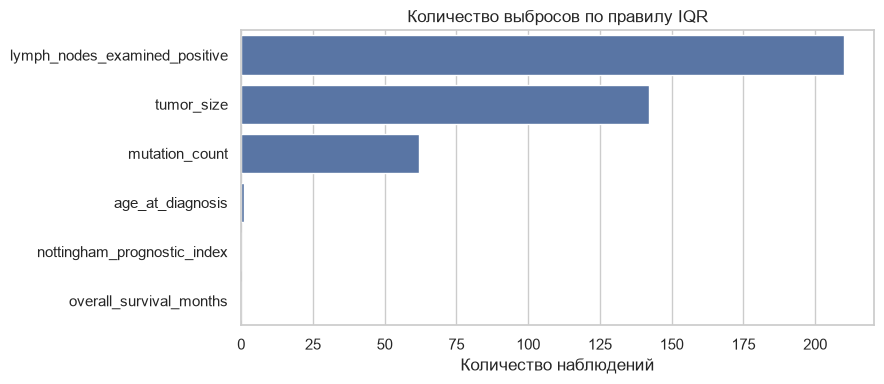

In [13]:
plt.figure(figsize=(9, 4))
sns.barplot(
    data=outlier_summary,
    x="Количество выбросов",
    y="Признак",
)
plt.title("Количество выбросов по правилу IQR")
plt.xlabel("Количество наблюдений")
plt.ylabel("")
plt.tight_layout()
plt.show()

Проверки не нашли невозможных значений в выбранных клинических полях. По правилу IQR больше всего выбросов у числа положительных лимфоузлов — 210 наблюдений (11,03%), размера опухоли — 142 (7,54%) и числа мутаций — 62 (3,34%). Эти значения могут отражать реальные тяжёлые случаи, поэтому удалять их автоматически нельзя.

## 6. Мутации и корреляции

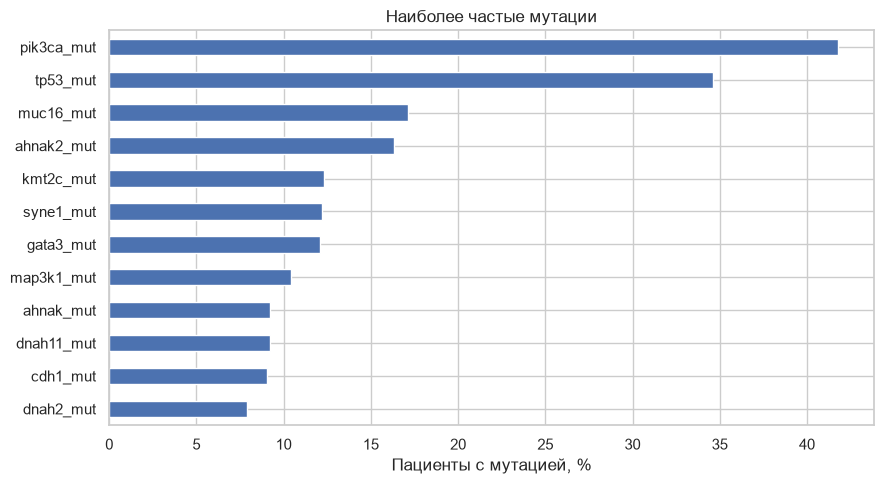

In [14]:
top_mutations = (
    df[mutation_columns]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .head(12)
    .sort_values()
)

plt.figure(figsize=(9, 5))
top_mutations.plot(kind="barh")
plt.title("Наиболее частые мутации")
plt.xlabel("Пациенты с мутацией, %")
plt.ylabel("")
plt.tight_layout()
plt.show()

Чаще всего встречаются признаки мутаций `PIK3CA` (41,75%) и `TP53` (34,61%). Это описательная частота внутри данного набора и не является оценкой частоты в общей популяции.

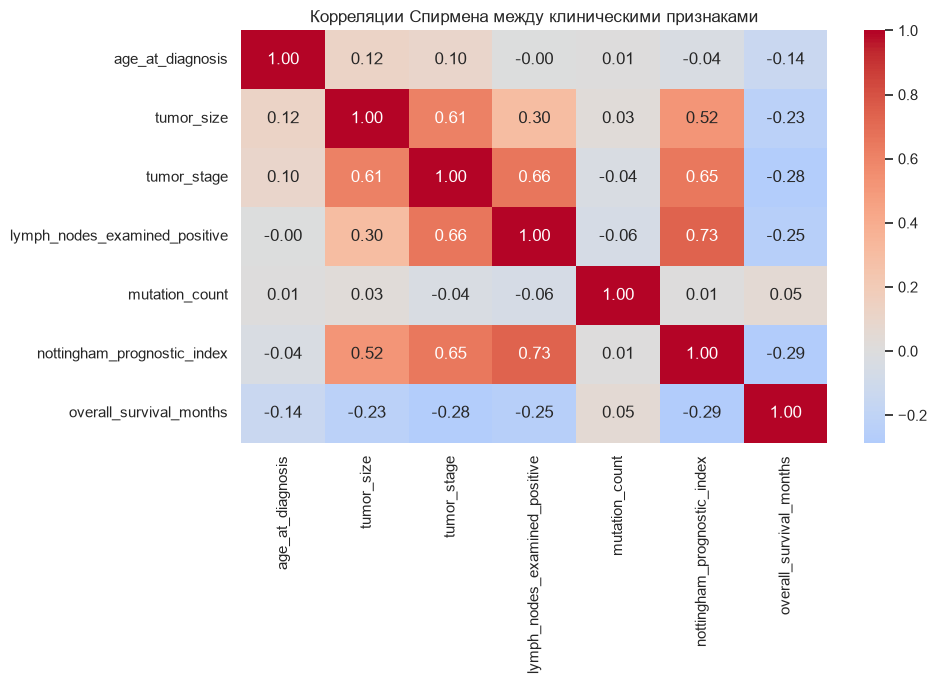

In [15]:
correlation = df[numeric_columns].astype(float).corr(method="spearman")

plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляции Спирмена между клиническими признаками")
plt.tight_layout()
plt.show()

Сильнее всего связаны Nottingham Prognostic Index и число положительных лимфоузлов (ρ≈0,73), стадия и число положительных лимфоузлов (ρ≈0,66), стадия и размер опухоли (ρ≈0,61). Продолжительность наблюдаемой выживаемости имеет умеренную отрицательную связь с этими показателями. Корреляции не доказывают причинность.

## 7. Итоговые выводы

1. Датасет содержит 1904 уникальных наблюдения и 693 признака. Полных дубликатов и повторных `patient_id` нет.
2. Общая полнота данных высокая, но пропуски распределены неравномерно. Перед моделированием особенно важно обработать `tumor_stage`, `3-gene_classifier_subtype` и другие клинические поля.
3. Выбранные проверки диапазонов не выявили невозможных значений. IQR-выбросы встречаются в показателях опухоли, лимфоузлов и числа мутаций; их нужно исследовать, а не удалять автоматически.
4. Категориальные признаки несбалансированы. Например, в `cancer_type` присутствует только один случай Breast Sarcoma, а HER2-положительных наблюдений значительно меньше отрицательных.
5. Клинические показатели стадии, размера опухоли, лимфоузлов и Nottingham Prognostic Index связаны между собой. Это нужно учитывать при выборе признаков для будущих моделей.
6. Данные подходят для дальнейшего анализа после обработки пропусков и осознанной работы с редкими категориями и выбросами.